# KOSMOS 설계 v2 — 본실험 (DeepSeek · Haiku)

**자료 구조**: 개수 텐서 `C[모델, 페르소나, 문항, 선지]`, 사람 분포 `H[페르소나, 문항, 선지]`.
보기 수가 문항마다 달라(2~7개) 선지 축을 7칸으로 맞추고 `MASK[문항, 선지]`로 실제 보기만 표시한다.

**보정**: `p ∝ (c + α)^β` (라플라스 α = 1). β 하나만 훈련 문항에서 고른다.

| 단계 | 내용 |
|---|---|
| 전처리 | 문항 축 → 사람 정답지 → 모델 개수 텐서 → 공통 함수 |
| 본실험 1 | β 그리드 한 번 평가 (β = 1, ¾, β* 모두 이 안에 있다) |
| 본실험 2 | β* 고정 → test 지표 |
| 본실험 3 | 민감 문항과 최빈값 붕괴 |
| 미리보기 | EXAONE 중간 결과 (세 모델 같은 k, test 제외) |
| 해석 | 쏠림(엔트로피), 페르소나 단계 효과, 최빈값 정확도, BPR식 쌍별 순위 |

In [1]:
import json, hashlib, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "inventory/kgss_clean.parquet").exists())
DESIGN = ROOT / "research/design_v2_20261112"
OUT = DESIGN / "analysis/out_calib"; (OUT / "figs").mkdir(parents=True, exist_ok=True)

MODELS = {"deepseek": ROOT / "raw/v2/deepseek_ultrafast_p1.jsonl",
          "haiku":    ROOT / "raw/v2/haiku_p1.jsonl"}
ALPHA = 1.0                                           # 라플라스
BETAS = np.round(np.arange(0.05, 1.5001, 0.005), 3)   # β = 1/T 그리드 (1과 0.75 포함)
RUN_TEST = True                                       # β*를 고정 파일에 기록한 뒤에만 True
rng = np.random.default_rng(20261112)
plt.rcParams.update({"font.family": "AppleGothic", "axes.unicode_minus": False,
                     "axes.spines.top": False, "axes.spines.right": False})

# 전처리

### 1. 문항 축과 선지 마스크

In [2]:
items = pd.read_csv(DESIGN / "item_manifest_v2.csv", encoding="utf-8-sig")
items["codes"] = items["codes"].apply(json.loads)

I = len(items)
K = items["codes"].str.len().max()

CODES = np.full((I, K), np.nan)                  # 선지 코드값 (빈 칸 nan)
for i, codes in enumerate(items["codes"]):
    CODES[i, :len(codes)] = codes
MASK = ~np.isnan(CODES)                          # 실제 있는 보기
UNIF = MASK / MASK.sum(1, keepdims=True)         # 균등분포 기준선

SPLIT = {s: (items["split_60_20_20"] == s).to_numpy() for s in ["calibration", "validation", "test"]}
ORDINAL = items["scale_type"].isin(["ordinal_monotone", "binary"]).to_numpy()   # W1 계산 대상
print(f"문항 {I}개, 선지 최대 {K}개 |", {s: int(m.sum()) for s, m in SPLIT.items()})

문항 246개, 선지 최대 7개 | {'calibration': 148, 'validation': 49, 'test': 49}


### 2. 페르소나 축과 사람 정답지 `H` (KGSS 2023, FINALWT 가중)

In [3]:
cells = pd.read_csv(DESIGN / "cells.csv", encoding="utf-8-sig").query("level == 'L1'").reset_index(drop=True)
PERSONAS = ["c0", "L0", *cells["cell_id"]]
L1 = slice(2, None)                                              # 페르소나 축에서 L1 10셀

kgss = pd.read_parquet(ROOT / "inventory/kgss_clean.parquet").query("YEAR == 2023")
kgss = kgss.assign(age_band=pd.cut(kgss["AGE"], [18, 30, 40, 50, 60, 200], right=False,
                                   labels=["18-29", "30-39", "40-49", "50-59", "60+"]).astype(str))
SEX = {"남자": 1, "여자": 2}
respondents = {"c0": kgss, "L0": kgss} | {
    c.cell_id: kgss[(kgss["SEX"] == SEX[c.sex]) & (kgss["age_band"] == c.age_band)] for c in cells.itertuples()}

def weighted_dist(df, var, codes):
    # 문항 하나의 가중 응답 분포 (선지 축 K칸)
    d = df[[var, "FINALWT"]].dropna()
    d = d[d[var].isin(codes[~np.isnan(codes)])]
    w = d.groupby(var)["FINALWT"].sum()
    return np.nan_to_num(w.reindex(codes).to_numpy()) / w.sum()

H = np.array([[weighted_dist(respondents[p], v, CODES[i]) for i, v in enumerate(items["var"])] for p in PERSONAS])
assert np.allclose(H.sum(-1), 1)
print("H", H.shape)

H (12, 246, 7)


### 3. 모델 개수 텐서 `C` (api_error 제외, 같은 표본 번호 중복은 처음 것, `k_cap`을 주면 앞 k개 표본만)

In [4]:
P_IDX = {p: j for j, p in enumerate(PERSONAS)}
I_IDX = {v: i for i, v in enumerate(items["var"])}
K_IDX = [{c: k for k, c in enumerate(codes)} for codes in items["codes"]]

def load_counts(path, k_cap=None):
    counts = np.zeros((len(PERSONAS), I, K), dtype=np.int32)
    seen = set()
    for line in open(path, encoding="utf-8"):
        r = json.loads(line)
        key = (r["probe_id"], r["sample_idx"])
        if r.get("invalid_type") == "api_error" or key in seen or (k_cap and r["sample_idx"] >= k_cap):
            continue
        seen.add(key)
        if r["valid"]:
            i = I_IDX[r["var"]]
            counts[P_IDX[r["cell_id"]], i, K_IDX[i][r["parsed"]]] += 1
    return counts

M = list(MODELS)
C = np.stack([load_counts(path) for path in MODELS.values()])     # [m, p, i, k]
print("C", C.shape, "| 유효 응답", dict(zip(M, C.sum((1, 2, 3)))))

C (2, 12, 246, 7) | 유효 응답 {'deepseek': np.int64(295158), 'haiku': np.int64(290643)}


### 4. 공통 함수
모든 함수는 앞쪽 축이 몇 개든 `[..., 페르소나, 문항, 선지]` → `[..., 단계, 문항]`으로 동작한다.
단계 3개: `c0`, `L0`, `L1cell`(10셀 각각의 지표를 평균).

In [5]:
LEVELS = ["c0", "L0", "L1cell"]

def to_prob(C, beta=1.0):
    x = (C + ALPHA * MASK) ** beta * MASK
    return x / x.sum(-1, keepdims=True)

def tvd(p, h):
    return 0.5 * np.abs(p - h).sum(-1)

def w1(p, h):
    # 정규화 Wasserstein-1: 누적분포 차이 × 코드 간격 / 척도 범위 (서열형·이진형만)
    gap = np.nan_to_num(np.diff(CODES, axis=1))
    span = np.nanmax(CODES, 1) - np.nanmin(CODES, 1)
    d = np.abs(np.cumsum(p, -1) - np.cumsum(h, -1))[..., :-1]
    return np.where(ORDINAL, (d * gap).sum(-1) / span, np.nan)

def mode_hit(p, h):
    top = lambda x: np.where(MASK, x, -np.inf).argmax(-1)
    return (top(p) == top(h)).astype(float)

METRICS = {"tvd": tvd, "w1": w1, "mode": mode_hit}

def evaluate(P):
    # P[..., p, i, k] → {지표: [..., 단계, 문항]}
    return {name: np.stack([f(P[..., 0, :, :], H[0]), f(P[..., 1, :, :], H[1]), f(P[..., L1, :, :], H[L1]).mean(-2)], -2)
            for name, f in METRICS.items()}

def mean_ci(x, B=5000):
    # 문항 축 평균과 부트스트랩 95% 구간 (nan 문항 제외)
    x = x[~np.isnan(x)]
    boot = x[rng.integers(0, len(x), (B, len(x)))].mean(1)
    return x.mean(), *np.percentile(boot, [2.5, 97.5])

# 본실험

### 1. β 그리드를 한 번에 평가하고 훈련 문항에서 β* 고르기

In [6]:
G = evaluate(to_prob(C[None], BETAS[:, None, None, None, None]))      # 지표 → [β, m, 단계, 문항]
ib_star = G["tvd"][..., SPLIT["calibration"]].mean(-1).argmin(0)     # [m, 단계]

In [7]:
# β* 고정 기록: 파일이 있으면 그 값을 쓰고, 새로 고른 값과 다르면 멈춘다
frozen_path = OUT / "frozen_beta.json"
sha = hashlib.sha256(C.tobytes()).hexdigest()
if frozen_path.exists():
    frozen = json.loads(frozen_path.read_text())
    assert frozen["counts_sha256"] == sha, "개수 텐서가 고정 당시와 다르다"
    frozen_beta = np.array([[frozen["beta"][f"laplace|{m}|{lv}"] for lv in LEVELS] for m in M])
    assert np.allclose(frozen_beta, BETAS[ib_star]), "다시 고른 β*가 고정값과 다르다"
else:
    frozen_path.write_text(json.dumps({"frozen_at": datetime.datetime.now().isoformat(timespec="seconds"),
        "counts_sha256": sha, "beta": {f"laplace|{m}|{lv}": float(BETAS[ib_star[a, l]])
                                       for a, m in enumerate(M) for l, lv in enumerate(LEVELS)}}, indent=1))
pd.DataFrame(BETAS[ib_star], index=M, columns=LEVELS).rename_axis("β*")

,c0,L0,L1cell
β*,,,
deepseek,0.315,0.315,0.31
haiku,0.240,0.245,0.25


### 2. 지표 표: β = 1, ¾, β* × 페르소나 × 지표

In [8]:
SETTINGS = {"β=1": np.full_like(ib_star, np.argmin(abs(BETAS - 1))),
            "β=0.75": np.full_like(ib_star, np.argmin(abs(BETAS - 0.75))),
            "β*": ib_star}
pick = lambda g, ib: np.take_along_axis(g, ib[None, ..., None], 0)[0]      # [β, m, l, i] → [m, l, i]

def table(split):
    rows = []
    for met, g in G.items():
        for setting, ib in SETTINGS.items():
            x = pick(g, ib)
            for a, m in enumerate(M):
                for l, lv in enumerate(LEVELS):
                    mean, lo, hi = mean_ci(x[a, l, SPLIT[split]])
                    rows.append(dict(metric=met, model=m, level=lv, setting=setting, mean=mean, lo=lo, hi=hi))
    unif = evaluate(np.broadcast_to(UNIF, (len(PERSONAS), I, K)))
    rows += [dict(metric=met, model="균등분포", level=lv, setting="", mean=np.nanmean(g[l, SPLIT[split]]))
             for met, g in unif.items() if met != "mode" for l, lv in enumerate(LEVELS)]
    return pd.DataFrame(rows)

if RUN_TEST:
    test = table("test"); test.to_csv(OUT / "v2_test_metrics.csv", index=False)
    for met in METRICS:
        display(test[test.metric == met].pivot_table(index="level", columns=["model", "setting"], values="mean", sort=False)
                .reindex(LEVELS).style.format("{:.3f}").set_caption(f"test · {met}"))

model,deepseek,haiku,deepseek,haiku,deepseek,haiku,균등분포
setting,β=1,β=1,β=0.75,β=0.75,β*,β*,
level,,,,,,,
c0,0.371,0.513,0.314,0.457,0.235,0.288,0.360
L0,0.361,0.485,0.305,0.429,0.228,0.271,0.360
L1cell,0.393,0.487,0.335,0.433,0.257,0.284,0.372


model,deepseek,haiku,deepseek,haiku,deepseek,haiku,균등분포
setting,β=1,β=1,β=0.75,β=0.75,β*,β*,
level,,,,,,,
c0,0.146,0.193,0.123,0.168,0.115,0.143,0.183
L0,0.148,0.182,0.123,0.158,0.113,0.138,0.183
L1cell,0.156,0.184,0.133,0.161,0.121,0.140,0.191


model,deepseek,haiku,deepseek,haiku,deepseek,haiku
setting,β=1,β=1,β=0.75,β=0.75,β*,β*
level,,,,,,
c0,0.714,0.612,0.714,0.612,0.714,0.612
L0,0.612,0.633,0.612,0.633,0.612,0.633
L1cell,0.543,0.586,0.543,0.586,0.543,0.586


In [9]:
# 모델 차이 (test, 같은 문항, β*): Haiku − DeepSeek, 음수면 Haiku가 더 가깝다
if RUN_TEST:
    star = {met: pick(g, ib_star) for met, g in G.items()}
    diff = pd.DataFrame([dict(metric=met, level=lv, **dict(zip(["haiku−deepseek", "lo", "hi"], mean_ci((x[1, l] - x[0, l])[SPLIT["test"]]))))
                         for met, x in star.items() for l, lv in enumerate(LEVELS)])
    display(diff.pivot_table(index="level", columns="metric", values=["haiku−deepseek", "lo", "hi"], sort=False).round(3))

haiku−deepseek                   lo                   hi              
metric            tvd     w1   mode    tvd     w1   mode    tvd     w1   mode
level                                                                        
c0              0.053  0.028 -0.102  0.019  0.010 -0.265  0.088  0.046  0.061
L0              0.043  0.025  0.020  0.012  0.010 -0.143  0.074  0.039  0.184
L1cell          0.026  0.019  0.043 -0.001  0.006 -0.078  0.055  0.032  0.165

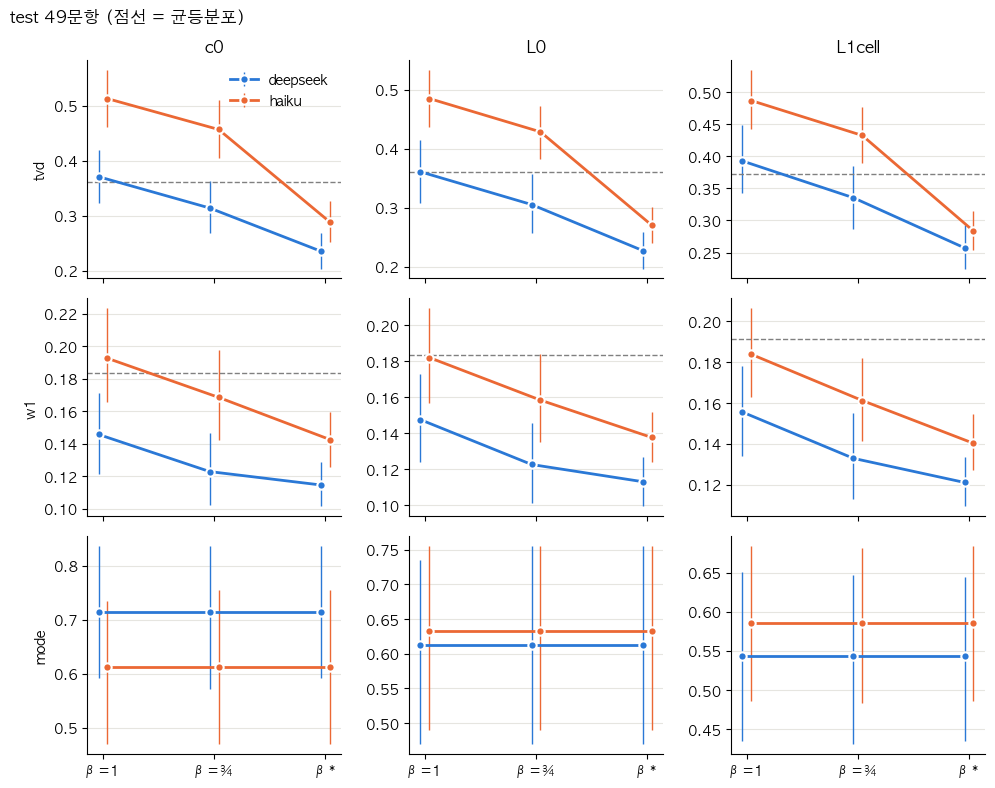

In [10]:
# 그림: 지표 3 × 페르소나 4, x = β 설정
if RUN_TEST:
    COL = {"deepseek": "#2a78d6", "haiku": "#eb6834"}
    fig, axs = plt.subplots(3, 3, figsize=(10, 8), sharex=True)
    for (r, met), (c, lv) in [(x, y) for x in enumerate(METRICS) for y in enumerate(LEVELS)]:
        ax, d = axs[r, c], test[(test.metric == met) & (test.level == lv)]
        for j, m in enumerate(M):
            e = d[d.model == m].set_index("setting").loc[list(SETTINGS)]
            ax.errorbar(np.arange(3) + 0.08 * (j - 0.5), e["mean"], [e["mean"] - e["lo"], e["hi"] - e["mean"]],
                        color=COL[m], marker="o", lw=2, elinewidth=1, mec="white", mew=1.5, label=m)
        if met != "mode":
            ax.axhline(d[d.model == "균등분포"]["mean"].iloc[0], ls="--", lw=1, c="gray")
        ax.set_xticks(range(3), ["β=1", "β=¾", "β*"]); ax.grid(axis="y", c="#e6e5e0")
        ax.set_title(lv if r == 0 else ""); ax.set_ylabel(met if c == 0 else "")
    axs[0, 0].legend(frameon=False); fig.suptitle("test 49문항 (점선 = 균등분포)", x=0.01, ha="left")
    plt.tight_layout(); fig.savefig(OUT / "figs/v2_metrics_grid.png", dpi=160, bbox_inches="tight")

### 3. 민감 문항과 최빈값 붕괴
가설: alignment 때문에 **민감한 문항일수록 모델이 한 보기로 더 강하게 쏠린다.**

- 민감도: jev-omni 4단계 점수의 확률 가중 평균(0~3). 교차 확인으로 decider-4b 점수도 본다.
- 쏠림 지표(보정 전 원비율 기준)
  - `top`: 모델 최빈 보기 비율
  - `excess`: 모델 최빈 비율 − 사람 최빈 비율 (사람이 원래 쏠린 문항을 걸러낸다)
  - `desirable`: 모델 최빈 보기가 바람직한 쪽 끝인가 (바람직한 끝이 정해진 문항만)
- 민감 문항 이분 기준이 아직 미정이라, 기준 없이 **순위 상관(스피어만)**과 **통제 회귀**(보기 수·사람 쏠림 통제)로 본다. 246문항 전부 사용(탐색 분석).

In [11]:
raw = C / np.maximum(C.sum(-1, keepdims=True), 1)                          # [m, p, i, k] 보정 전 원비율
first_or_last = np.where(items["desirable_end"] == "first", 0,
                np.where(items["desirable_end"] == "last", MASK.sum(1) - 1, -1))
top_k = lambda x: np.where(MASK, x, -np.inf).argmax(-1)

def collapse(view):
    # view: "c0" | "L0" | "L1"(셀 평균) → 문항 단위 데이터프레임
    sel = {"c0": [0], "L0": [1], "L1": list(range(2, len(PERSONAS)))}[view]
    rows = []
    for a, m in enumerate(M):
        p, h = raw[a, sel], H[sel]
        rows.append(pd.DataFrame({"model": m, "view": view, "var": items["var"],
            "sens": items["sensitivity_level"], "sens_decider": items["sensitivity_level_decider"],
            "n_opt": MASK.sum(1), "human_top": h.max(-1).mean(0),
            "top": p.max(-1).mean(0), "excess": (p.max(-1) - h.max(-1)).mean(0),
            "desirable": np.where(first_or_last >= 0, (top_k(p) == first_or_last).mean(0), np.nan),
            "human_desirable": np.where(first_or_last >= 0, (top_k(h) == first_or_last).mean(0), np.nan)}))
    return pd.concat(rows)

col = pd.concat([collapse(v) for v in ["c0", "L0", "L1"]])
col["sens_bin"] = pd.cut(col["sens"], [-1, 1.0, 1.5, 2.0, 9], labels=["<1", "1–1.5", "1.5–2", "≥2"])
col.to_csv(OUT / "v2_sensitivity_collapse.csv", index=False)

In [12]:
def spearman(x, y):
    ok = x.notna() & y.notna()
    return x[ok].rank().corr(y[ok].rank())

def boot_spearman(d, x, y, B=1000):
    r = [spearman((s := d.sample(len(d), replace=True, random_state=b))[x], s[y]) for b in range(B)]
    return np.percentile(r, [2.5, 97.5])

rows = []
for (m, v), d in col.groupby(["model", "view"], sort=False):
    for y in ["top", "excess", "desirable"]:
        for x in ["sens", "sens_decider"]:
            lo, hi = boot_spearman(d, x, y) if x == "sens" else (np.nan, np.nan)
            rows.append(dict(model=m, view=v, y=y, x=x, rho=spearman(d[x], d[y]), lo=lo, hi=hi))
rho = pd.DataFrame(rows)
display(rho[rho.x == "sens"].pivot_table(index=["model", "view"], columns="y", values=["rho", "lo", "hi"], sort=False).round(2))
display(rho[rho.x == "sens_decider"].pivot_table(index=["model", "view"], columns="y", values="rho", sort=False)
        .round(2).style.set_caption("교차 확인: decider-4b 민감도와의 스피어만 ρ"))

rho                     lo                     hi         \
y               top excess desirable   top excess desirable   top excess   
model    view                                                              
deepseek c0    0.03  -0.02      0.18 -0.10  -0.15      0.02  0.15   0.12   
         L0    0.01  -0.01      0.07 -0.11  -0.14     -0.06  0.14   0.12   
         L1    0.08   0.06      0.16 -0.06  -0.07      0.02  0.22   0.19   
haiku    c0    0.11   0.07      0.09 -0.01  -0.07     -0.05  0.24   0.21   
         L0    0.02  -0.03      0.17 -0.11  -0.16      0.03  0.15   0.10   
         L1    0.01  -0.02      0.15 -0.12  -0.15      0.02  0.14   0.12   

                         
y             desirable  
model    view            
deepseek c0        0.32  
         L0        0.21  
         L1        0.30  
haiku    c0        0.23  
         L0        0.31  
         L1        0.28

In [13]:
# 민감도 구간별 평균
base = col[col.model == M[0]].groupby(["view", "sens_bin"], observed=True)
by_bin = col.pivot_table(index=["view", "sens_bin"], columns="model", values=["top", "excess", "desirable"], observed=True, sort=False)
by_bin[("사람", "top")] = base["human_top"].mean()
by_bin[("사람", "desirable")] = base["human_desirable"].mean()
by_bin[("문항", "n")] = base.size()
display(by_bin.round(3))

top          excess        desirable            사람  \
model         deepseek  haiku deepseek  haiku  deepseek  haiku    top   
view sens_bin                                                           
c0   1.5–2       0.804  0.935    0.276  0.406     0.205  0.220  0.529   
     <1          0.847  0.839    0.303  0.295     0.188  0.219  0.544   
     ≥2          0.828  0.894    0.271  0.337     0.458  0.292  0.556   
     1–1.5       0.804  0.934    0.326  0.457     0.139  0.111  0.478   
L0   1.5–2       0.823  0.915    0.295  0.386     0.181  0.205  0.529   
     <1          0.837  0.866    0.293  0.321     0.188  0.156  0.544   
     ≥2          0.776  0.847    0.220  0.291     0.250  0.417  0.556   
     1–1.5       0.812  0.934    0.334  0.457     0.111  0.139  0.478   
L1   1.5–2       0.828  0.933    0.288  0.393     0.176  0.177  0.540   
     <1          0.776  0.907    0.212  0.343     0.138  0.162  0.563   
     ≥2          0.790  0.877    0.225  0.313     0.275  0.283  0.565   
     1–1.5       0.804  0.931    0.309  0.436     0.131  0.117  0.495   

                          문항  
model         desirable    n  
view sens_bin                 
c0   1.5–2        0.126  135  
     <1           0.062   46  
     ≥2           0.583   24  
     1–1.5        0.000   41  
L0   1.5–2        0.126  135  
     <1           0.062   46  
     ≥2           0.583   24  
     1–1.5        0.000   41  
L1   1.5–2        0.131  135  
     <1           0.072   46  
     ≥2           0.596   24  
     1–1.5        0.014   41

In [14]:
# 통제 회귀: excess ~ 민감도 + 보기 수 + 사람 최빈 비율 (표준화 계수, 부트스트랩 95% 구간)
def std_ols(d, y="excess", xs=("sens", "n_opt", "human_top")):
    Z = d[list(xs)].apply(lambda s: (s - s.mean()) / s.std())
    X = np.column_stack([np.ones(len(d)), Z.values])
    yz = (d[y] - d[y].mean()) / d[y].std()
    return np.linalg.lstsq(X, yz.values, rcond=None)[0][1:]

rows = []
for (m, v), d in col.groupby(["model", "view"], sort=False):
    b = std_ols(d)
    boot = np.array([std_ols(d.sample(len(d), replace=True, random_state=s)) for s in range(1000)])
    lo, hi = np.percentile(boot[:, 0], [2.5, 97.5])
    rows.append(dict(model=m, view=v, beta_sens=b[0], lo=lo, hi=hi, beta_nopt=b[1], beta_human_top=b[2]))
display(pd.DataFrame(rows).round(3))

,model,view,beta_sens,lo,hi,beta_nopt,beta_human_top
0,deepseek,c0,-0.023,-0.122,0.074,-0.023,-0.635
1,haiku,c0,0.148,0.027,0.262,-0.033,-0.716
2,deepseek,L0,0.000,-0.110,0.107,-0.010,-0.593
3,haiku,L0,0.042,-0.066,0.149,0.027,-0.649
4,deepseek,L1,0.110,-0.003,0.223,-0.018,-0.643
5,haiku,L1,0.000,-0.072,0.073,-0.039,-0.861


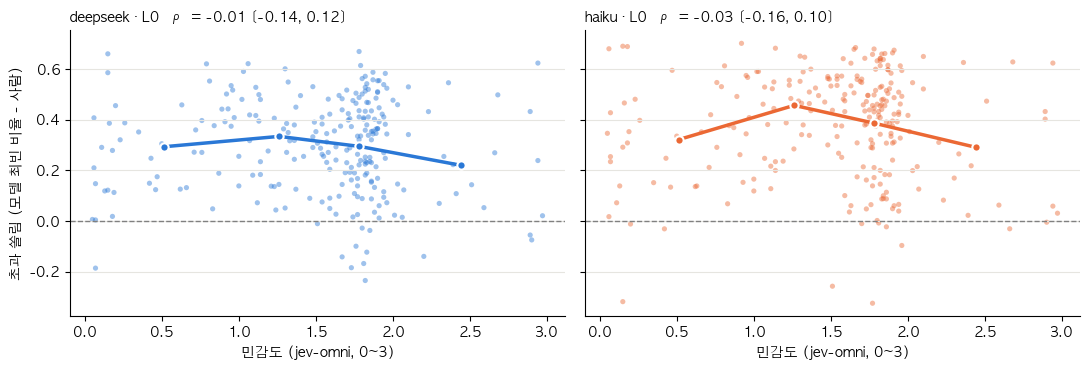

In [15]:
# 그림: 민감도 vs 초과 쏠림 (L0), 구간 평균 선
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
COL = {"deepseek": "#2a78d6", "haiku": "#eb6834"}
for ax, m in zip(axs, M):
    d = col[(col.model == m) & (col.view == "L0")]
    ax.scatter(d["sens"], d["excess"], s=14, alpha=0.45, color=COL[m], edgecolor="none")
    g = d.groupby("sens_bin", observed=True).agg(x=("sens", "mean"), y=("excess", "mean"))
    ax.plot(g["x"], g["y"], color=COL[m], lw=2.5, marker="o", mec="white", mew=1.5)
    ax.axhline(0, c="gray", lw=1, ls="--")
    r = rho[(rho.model == m) & (rho.view == "L0") & (rho.y == "excess") & (rho.x == "sens")].iloc[0]
    ax.set_title(f"{m} · L0   ρ = {r.rho:.2f} [{r.lo:.2f}, {r.hi:.2f}]", loc="left", fontsize=10)
    ax.set_xlabel("민감도 (jev-omni, 0~3)"); ax.grid(axis="y", c="#e6e5e0")
axs[0].set_ylabel("초과 쏠림 (모델 최빈 비율 - 사람)")
plt.tight_layout(); fig.savefig(OUT / "figs/v2_sensitivity_excess.png", dpi=160, bbox_inches="tight")

### 미리보기: EXAONE 중간 결과
EXAONE은 아직 표본이 적다. 표본 수가 다르면 평활화 영향이 달라 비교가 안 되므로, **세 모델 모두 앞 `K_PREVIEW`개 표본만** 써서 같은 절차(훈련에서 β*)를 돌린다.
EXAONE의 최종 test 평가는 k=100이 모인 뒤 한 번만 하기 위해, 여기서는 **검증 분할만** 본다.

In [16]:
EXAONE = DESIGN / "team_packages/KOSMOS_EXAONE_m1_태우/exaone_m1_p1.jsonl"
K_PREVIEW = 7
MP = [*M, "exaone"]
CP = np.stack([load_counts(p, k_cap=K_PREVIEW) for p in [*MODELS.values(), EXAONE]])
print("프롬프트당 유효 표본(평균):", dict(zip(MP, CP.sum(-1).mean((1, 2)).round(2))))

GP = evaluate(to_prob(CP[None], BETAS[:, None, None, None, None]))
ibp = GP["tvd"][..., SPLIT["calibration"]].mean(-1).argmin(0)
i1 = np.full_like(ibp, np.argmin(abs(BETAS - 1)))
preview = pd.DataFrame([dict(model=m, level=lv, metric=met, setting=s, beta=BETAS[ib[a, l]],
                             value=np.nanmean(pick(g, ib)[a, l, SPLIT["validation"]]))
                        for met, g in GP.items() for s, ib in {"β=1": i1, "β*": ibp}.items()
                        for a, m in enumerate(MP) for l, lv in enumerate(LEVELS)])
display(pd.DataFrame(BETAS[ibp], index=MP, columns=LEVELS).rename_axis(f"β* (k={K_PREVIEW})"))
for met in METRICS:
    display(preview[preview.metric == met].pivot_table(index="level", columns=["setting", "model"], values="value", sort=False)
            .reindex(LEVELS).style.format("{:.3f}").set_caption(f"검증 · {met} · k={K_PREVIEW}"))

프롬프트당 유효 표본(평균): {'deepseek': np.float64(7.0), 'haiku': np.float64(6.9), 'exaone': np.float64(6.97)}


,c0,L0,L1cell
β* (k=7),,,
deepseek,0.595,0.595,0.57
haiku,0.520,0.535,0.52
exaone,0.585,0.645,0.68


# 해석
β와 무관한 지표(엔트로피·최빈값·순위)는 **246문항 전부**로 본다. β* 보정 TVD는 test 49문항 값이다.

### 1. 쏠림: 정규화 엔트로피 (0 = 한 보기에 몰림, 1 = 균등)

In [17]:
def norm_entropy(p):
    return -(p * np.log(np.where(p > 0, p, 1))).sum(-1) / np.log(MASK.sum(1))

def by_level(x):
    # [..., p, i] → [..., 단계]  (L1cell은 셀과 문항 평균)
    return np.stack([np.nanmean(x[..., 0, :], -1), np.nanmean(x[..., 1, :], -1), np.nanmean(x[..., L1, :], (-1, -2))], -1)

share = lambda C: C / np.maximum(C.sum(-1, keepdims=True), 1)     # 보정 전 원비율
R100, R7 = share(C), share(CP)                                     # k=100 (DeepSeek·Haiku), k=7 (세 모델)
H7 = share(rng.multinomial(7, H, size=(200, *H.shape[:-1])))       # 사람 분포에서 7개씩 뽑았을 때 (표본 편향 비교용)

entropy = pd.DataFrame({**{f"{m} k=100": by_level(norm_entropy(R100[a])) for a, m in enumerate(M)},
                        "사람": by_level(norm_entropy(H)),
                        **{f"{m} k=7": by_level(norm_entropy(R7[a])) for a, m in enumerate(MP)},
                        "사람 k=7": by_level(norm_entropy(H7)).mean(0)}, index=LEVELS)
display(entropy.style.format("{:.3f}").set_caption("평균 정규화 엔트로피"))
display(pd.DataFrame({m: by_level((R100[a].max(-1) >= 0.9).astype(float)) for a, m in enumerate(M)} | {"사람": by_level((H.max(-1) >= 0.9).astype(float))},
                     index=LEVELS).style.format("{:.0%}").set_caption("최빈 보기 비율 ≥ 90%인 문항 비율 (k=100)"))

,deepseek k=100,haiku k=100,사람,deepseek k=7,haiku k=7,exaone k=7,사람 k=7
c0,0.329,0.152,0.743,0.277,0.098,0.200,0.587
L0,0.317,0.160,0.743,0.251,0.128,0.282,0.587
L1cell,0.327,0.134,0.720,0.262,0.107,0.275,0.571


,deepseek,haiku,사람
c0,46%,76%,3%
L0,43%,72%,3%
L1cell,41%,76%,4%


### 2. 페르소나 단계를 올리면 (c0 → L0 → L1)

In [18]:
i_one = np.argmin(abs(BETAS - 1))
star = {met: pick(g, ib_star) for met, g in G.items()}
ladder = pd.concat({m: pd.DataFrame({
    "엔트로피": by_level(norm_entropy(R100[a])),
    "최빈 비율": by_level(R100[a].max(-1)),
    "무효율": by_level(1 - C[a].sum(-1) / 100),
    "TVD β=1 (전체)": G["tvd"][i_one, a].mean(-1),
    "TVD β* (test)": star["tvd"][a][:, SPLIT["test"]].mean(-1),
    "최빈값 정확도": G["mode"][i_one, a].mean(-1),
    "β*": BETAS[ib_star[a]]}, index=LEVELS) for a, m in enumerate(M)})
display(ladder.style.format("{:.3f}").format("{:.1%}", subset=["무효율"]))

In [19]:
# L1 셀끼리 얼마나 다르게 답하나: 셀 쌍 45개의 평균 TVD, 셀 평균점수의 퍼짐과 사람과의 상관 (서열형·이진형)
up = np.triu(np.ones((10, 10), bool), 1)
def between_cells(P):                                      # P[10, i, k]
    return tvd(P[:, None], P[None, :])[up].mean(0)         # [i]
mean_score = lambda P: (P * np.nan_to_num(CODES)).sum(-1)  # [..., i]
hm = mean_score(H[L1])
spread = pd.DataFrame({m: {
    "셀 간 평균 TVD": between_cells(R100[a, L1]).mean(),
    "셀 평균점수 SD (중앙값)": np.median(mean_score(R100[a, L1]).std(0)[ORDINAL]),
    "SD 비 모델/사람 (중앙값)": np.median((mean_score(R100[a, L1]).std(0) / hm.std(0))[ORDINAL]),
    "셀 평균점수 상관 (중앙값)": np.nanmedian([np.corrcoef(mean_score(R100[a, L1])[:, i], hm[:, i])[0, 1]
                                       if mean_score(R100[a, L1])[:, i].std() > 0 else np.nan for i in np.where(ORDINAL)[0]]),
    "L0 대비 셀 평균 이동 TVD": tvd(R100[a, L1], R100[a, 1]).mean()} for a, m in enumerate(M)})
spread["사람"] = [between_cells(H[L1]).mean(), np.median(hm.std(0)[ORDINAL]), 1.0, 1.0, tvd(H[L1], H[0]).mean()]
display(spread.style.format("{:.3f}"))

,deepseek,haiku,사람
셀 간 평균 TVD,0.169,0.192,0.116
셀 평균점수 SD (중앙값),0.128,0.118,0.100
SD 비 모델/사람 (중앙값),1.221,0.941,1.000
셀 평균점수 상관 (중앙값),0.258,0.184,1.000
L0 대비 셀 평균 이동 TVD,0.201,0.236,0.079


### 3. 분포는 맞는데 최빈값은 왜 자주 틀리나

In [20]:
top = lambda x: np.where(MASK, x, -np.inf).argmax(-1)
srt = np.sort(H, -1)
margin = srt[..., -1] - srt[..., -2]                                   # 사람 1위 − 2위 비율 차 [p, i]
n_resp = np.array([1230, 1230, *cells["n"]])
H_boot = share(rng.multinomial(n_resp[None, :, None], H, size=(200, *H.shape[:-1])))   # 사람 재표집
second = np.argsort(np.where(MASK, R100, -np.inf), -1)[..., -2]

mode_tbl = pd.DataFrame({
    **{m: by_level(top(R100[a]) == top(H)) for a, m in enumerate(M)},
    **{f"{m} 상위2 안": by_level((top(R100[a]) == top(H)) | (second[a] == top(H))) for a, m in enumerate(M)},
    "우연 (1/보기 수)": by_level(np.broadcast_to(1 / MASK.sum(1), H.shape[:-1])),
    "항상 1번": by_level(top(H) == 0),
    "사람 재표집 (상한)": by_level(top(H_boot) == top(H)).mean(0)}, index=LEVELS)
display(mode_tbl.style.format("{:.1%}").set_caption("최빈값 정확도와 기준선"))

bins = pd.cut(margin.ravel(), [0, 0.05, 0.15, 0.3, 1], include_lowest=True)
by_margin = pd.DataFrame({m: pd.Series((top(R100[a]) == top(H)).ravel()).groupby(bins, observed=True).mean() for a, m in enumerate(M)})
by_margin["사람 재표집"] = pd.Series((top(H_boot) == top(H)).mean(0).ravel()).groupby(bins, observed=True).mean()
by_margin["비중"] = pd.Series(bins).value_counts(normalize=True).sort_index().values
display(by_margin.style.format("{:.1%}").set_caption("사람 1·2위 격차별 최빈값 정확도 (페르소나 12 × 문항 246)"))

,deepseek,haiku,deepseek 상위2 안,haiku 상위2 안,우연 (1/보기 수),항상 1번,사람 재표집 (상한)
c0,53.3%,54.5%,81.7%,73.2%,25.4%,11.8%,96.1%
L0,52.4%,54.9%,82.1%,76.8%,25.4%,11.8%,96.0%
L1cell,49.1%,56.5%,79.3%,75.9%,25.4%,12.5%,90.1%


,deepseek,haiku,사람 재표집,비중
"(-0.001, 0.05]",34.6%,40.7%,63.5%,15.7%
"(0.05, 0.15]",41.2%,50.7%,88.3%,24.3%
"(0.15, 0.3]",48.5%,61.1%,98.7%,27.1%
"(0.3, 1.0]",64.3%,63.6%,100.0%,33.0%


### 4. BPR식 쌍별 대소관계
BPR처럼 "a가 b보다 크다"는 **쌍의 순서**만 본다. 사람 쪽 차이가 0인 쌍은 빼고, 모델 동점은 0.5.
- **AUC**: 맞춘 쌍의 비율 (우연 0.5)
- **가중 AUC**: 쌍마다 사람 쪽 차이 크기 |h_a − h_b|로 가중. 사람이 거의 같다고 본 쌍(표집 오차 안일 가능성이 큰 쌍)은 영향이 작아져, 미정인 동점 규칙을 따로 정하지 않아도 된다.
- 지수 보정은 한 분포 안의 순서를 바꾸지 않으므로 선지 간 AUC는 β와 무관하다. 원비율(k=100)로 계산.

In [21]:
def pair_auc(dm, dh, valid):
    # dm, dh: 모델·사람 쌍 차이, valid: 쓸 쌍 → (AUC, 가중 AUC), 쌍 축은 앞쪽에서 모두 합친다
    s = np.where(np.sign(dm) == np.sign(dh), 1.0, np.where(dm == 0, 0.5, 0.0))
    v = valid & (dh != 0)
    w = np.abs(dh) * v
    return (s * v).sum() / v.sum(), (s * w).sum() / w.sum()

def option_pairs(p, h):
    # 같은 페르소나·문항 안의 보기 쌍
    d = lambda x: x[..., :, None] - x[..., None, :]
    valid = np.triu(np.ones((K, K), bool), 1) & MASK[:, :, None] & MASK[:, None, :]
    return d(p), d(h), np.broadcast_to(valid, d(h).shape)

rows = []
for a, m in enumerate(M):
    for l, sel in enumerate([[0], [1], list(range(2, len(PERSONAS)))]):
        rows.append(dict(model=m, level=LEVELS[l], 비교="선지 간", **dict(zip(["AUC", "가중 AUC"], pair_auc(*option_pairs(R100[a, sel], H[sel]))))))
# 기준선: L1 셀마다 모집단 사람 분포의 보기 순서를 그대로 쓰기
base = pair_auc(*option_pairs(np.broadcast_to(H[0], H[L1].shape), H[L1]))
rows.append(dict(model="기준선: 모집단 순서", level="L1cell", 비교="선지 간", **dict(zip(["AUC", "가중 AUC"], base))))

# 페르소나 간: L1 10셀 중 두 셀을 비교 (평균점수, 서열형·이진형) / (보기별 비율, 전체 문항)
sex = cells["sex"].to_numpy(); age = cells["age_band"].to_numpy()
kind = {"성별만 다름": age[:, None] == age[None, :], "연령만 다름": sex[:, None] == sex[None, :]}
cd = lambda x: x[:, None] - x[None, :]                                # 셀 쌍 차이 [10, 10, ...]
for a, m in enumerate(M):
    mm, hmm = mean_score(R100[a, L1]), mean_score(H[L1])
    v = (up[..., None] & ORDINAL[None, None, :])
    rows.append(dict(model=m, level="L1", 비교="페르소나 간 · 평균점수", **dict(zip(["AUC", "가중 AUC"], pair_auc(cd(mm), cd(hmm), v)))))
    for name, km in kind.items():
        rows.append(dict(model=m, level="L1", 비교=f"페르소나 간 · 평균점수 · {name}",
                         **dict(zip(["AUC", "가중 AUC"], pair_auc(cd(mm), cd(hmm), v & km[..., None])))))
    vo = up[..., None, None] & MASK[None, None]
    rows.append(dict(model=m, level="L1", 비교="페르소나 간 · 보기별 비율",
                     **dict(zip(["AUC", "가중 AUC"], pair_auc(cd(R100[a, L1]), cd(H[L1]), vo)))))
bpr = pd.DataFrame(rows); bpr.to_csv(OUT / "v2_bpr.csv", index=False)
display(bpr.set_index(["비교", "level", "model"]).style.format("{:.3f}"))